In [1]:
import polars as pl
import matplotlib.pyplot as plt

from glob import glob

In [2]:
file_list = glob("/home/n9985158/phd/euk-singlem/benchmarking_workflow/simple_simulated/outputs/euk-singlem/opal/*.opal_report")

sample_names = (
    [
        "sample_" + file_path.split('/euk')[-1].split('.')[0] for file_path in file_list
    ]
)

results = {}
results_abundance = {}

for name, path in zip(sample_names, file_list):
    df = (
        pl
        .read_csv(path, separator='\t')
        .filter(
            (pl.col('tool') != 'Gold standard')
        &   (pl.col('metric').is_in(['F1 score', 'Completeness']))
        )
        .drop(['tool', 'sample'])
        )

    results[name] = df

    df_abundance = (
        pl
        .read_csv(path, separator='\t')
        .filter(
            (pl.col('tool') != 'Gold standard')
        &   (pl.col('metric').is_in(['Bray-Curtis distance', 'Weighted UniFrac (CAMI)'])))
        .with_columns(
            pl.when(pl.col('metric') == 'Weighted UniFrac (CAMI)')
            .then(pl.col('value') / 14.0)
            .otherwise(pl.col('value'))
            .alias('value'),
            pl.when(pl.col('metric') == 'Weighted UniFrac (CAMI)')
            .then(pl.lit('Normalised Weighted\nUniFrac Distance'))
            .otherwise(pl.col('metric').str.to_titlecase())
            .alias('metric'),
        )
        .drop(['tool', 'sample'])
        )

    results_abundance[name] = df_abundance

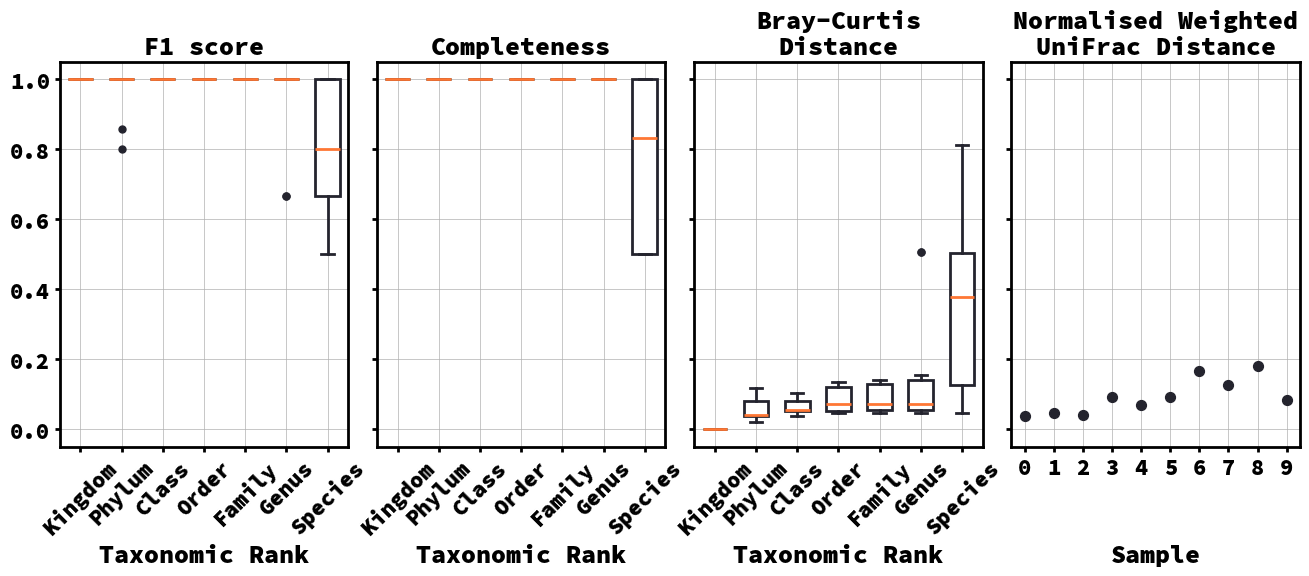

In [3]:
# map ranks to ints
rank_mapping = {
    'species': 1,
    'genus': 2,
    'family': 3,
    'order': 4,
    'class': 5,
    'phylum': 6,
    'kingdom': 7,
}

# Define your font size tweaks
font_tweaks = {
    'font.size': 18,          # Global font size
    'axes.labelsize': 18,     # X and Y label size
    'axes.titlesize': 18,     # Title size
    'xtick.labelsize': 16,    # X-axis tick labels
    'ytick.labelsize': 16     # Y-axis tick labels
}


all_results_unweighted = pl.concat(list(results.values()))
all_results_abundance = pl.concat(list(results_abundance.values()))

all_results = pl.concat([all_results_unweighted, all_results_abundance])
    
with plt.style.context(['~/mphil/code/modules/mplstyles/generic.mplstyle', font_tweaks]):


    # plot boxplots of the same data with ranks on the x-axis and values on the y-axis
    fig, axes = plt.subplots(1, 4, figsize=(16, 5), sharey=True)
    for metric, ax, sub_label in zip(['F1 score', 'Completeness', 'Bray-Curtis Distance', 'Normalised Weighted\nUniFrac Distance'], axes.flatten(), ['A', 'B', 'C', 'D']):
        
        if metric != 'Normalised Weighted\nUniFrac Distance':
            metric_df = (
                all_results
                .filter(pl.col('metric') == metric)
                .with_columns(pl.col('rank').replace(rank_mapping).alias('rank_num'))
                .sort('rank_num')
                )

            y_vals = [
                metric_df.filter(pl.col('rank_num') == rank_num)['value'].to_list()
                for rank_num in metric_df['rank_num'].unique().sort().to_list()
            ]

            order_labels = (
                metric_df.sort('rank_num')['rank'].str.to_titlecase().unique(maintain_order=True).to_list()
            )

            ax.boxplot(
                y_vals,
                tick_labels=order_labels,
                widths=0.6,
                patch_artist=True,
                boxprops=dict(facecolor='#fff', color='#24242e', linewidth=2),
                medianprops=dict(color='#FE7734', linewidth=2),
                whiskerprops=dict(color='#24242e', linewidth=2),
                capprops=dict(color='#24242e', linewidth=2),
                flierprops=dict(marker='o', markerfacecolor='#24242e', markeredgecolor='#24242e', markersize=5),
                label=metric
            )

            ax.invert_xaxis()
            ax.set_xlabel('Taxonomic Rank')
            ax.set_xticklabels(order_labels, rotation=45)


        else:
            # plot for each sample in its own column as a scatter plot without jitter
            combined_df = pl.concat([
                df.with_columns(pl.lit(name).alias('sample'))
                for name, df in results_abundance.items()
            ])

            # 2. Filter for the metric and parse the sample labels in one go
            plot_df = (
                combined_df
                .filter(pl.col('metric') == metric)
                .with_columns(
                    # Grabs the text after the last underscore
                    pl.col('sample').str.split('_').list.get(-1).alias('sample_label')
                )
                .sort('sample_label') # Optional: keeps your X-axis sorted consistently
            )

            # 3. Plot everything in a single vectorized call
            ax.scatter(
                plot_df['sample_label'].to_list(),
                plot_df['value'].to_list(),
                s=50,
                color='#24242e',
            )
            ax.set_xlabel('Sample')


        ax.set_ylim(-0.05, 1.05)

        if metric == 'Bray-Curtis Distance':
            metric = 'Bray-Curtis\nDistance'
        ax.set_title(metric)

        ax.set_axisbelow(True)
        ax.grid(True, which='both', linewidth=0.5)

        # ax.text(
        #     -0.02, 1.1, sub_label, 
        #     transform=ax.transAxes, 
        #     fontsize=24, fontweight='bold', color='#555', 
        #     va='top', ha='right')

    fig.subplots_adjust(wspace=0.1)
    fig.align_labels()
    # plt.tight_layout()
    plt.show()

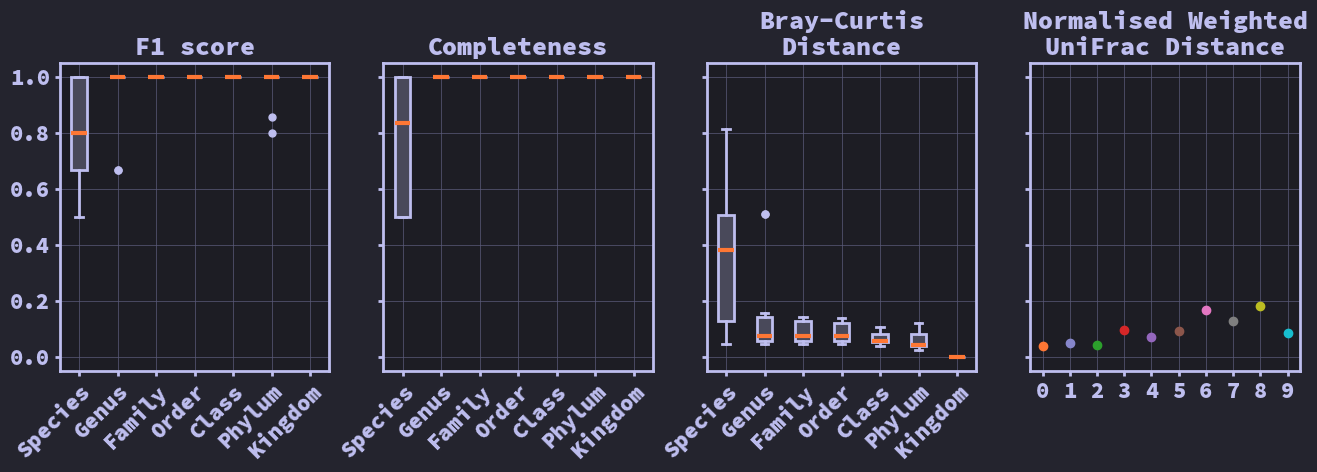

In [19]:
# map ranks to ints
rank_mapping = {
    'species': 1,
    'genus': 2,
    'family': 3,
    'order': 4,
    'class': 5,
    'phylum': 6,
    'kingdom': 7,
}

# Define your font size tweaks
font_tweaks = {
    'font.size': 18,          # Global font size
    'axes.labelsize': 18,     # X and Y label size
    'axes.titlesize': 18,     # Title size
    'xtick.labelsize': 16,    # X-axis tick labels
    'ytick.labelsize': 16     # Y-axis tick labels
}



all_results_unweighted = pl.concat(list(results.values()))
all_results_abundance = pl.concat(list(results_abundance.values()))

all_results = pl.concat([all_results_unweighted, all_results_abundance])
    
with plt.style.context(['~/mphil/code/modules/mplstyles/duotone_space.mplstyle', font_tweaks]):


    # plot boxplots of the same data with ranks on the x-axis and values on the y-axis
    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
    for metric, ax in zip(['F1 score', 'Completeness', 'Bray-Curtis Distance', 'Normalised Weighted\nUniFrac Distance'], axes.flatten()):
        
        if metric != 'Normalised Weighted\nUniFrac Distance':
            metric_df = (
                all_results
                .filter(pl.col('metric') == metric)
                .with_columns(pl.col('rank').replace(rank_mapping).alias('rank_num'))
                .sort('rank_num')
                )

            y_vals = [
                metric_df.filter(pl.col('rank_num') == rank_num)['value'].to_list()
                for rank_num in metric_df['rank_num'].unique().sort().to_list()
            ]

            order_labels = (
                metric_df.sort('rank_num')['rank'].str.to_titlecase().unique(maintain_order=True).to_list()
            )

            ax.boxplot(
                y_vals,
                tick_labels=order_labels,
                widths=0.4,
                patch_artist=True,
                boxprops=dict(facecolor='#49495a', color='#bebeef', linewidth=2),
                medianprops=dict(color='#FE7734', linewidth=3),
                whiskerprops=dict(color='#bebeef', linewidth=2),
                capprops=dict(color='#bebeef', linewidth=2),
                flierprops=dict(marker='o', markerfacecolor='#bebeef', markeredgecolor='#bebeef', markersize=5),
                label=metric
            )

            # ax.set_ylim(-0.05, 1.05)

            # ax.set_title(metric)
            # ax.set_xlabel('Taxonomic Rank')
            ax.set_xticklabels(order_labels, rotation=45, rotation_mode='anchor', ha='right')
            # ax.grid(True, which='both', linewidth=0.5, zorder=0)
            # ax.invert_xaxis()

            # if metric in ['Bray-Curtis distance']:
            #     ax.invert_yaxis()

        else:
            # plot for each sample in its own column as a scatter plot without jitter
            for name, df in sorted(results_abundance.items()):
                metric_df = (
                    df
                    .filter(pl.col('metric') == metric)
                    .with_columns(pl.lit(name).alias('sample'))
                )

                y_vals = metric_df['value'].to_list()
                sample_label = name.split('_')[-1]

                ax.scatter([sample_label] * len(y_vals), y_vals, label=name)



        ax.set_ylim(-0.05, 1.05)

        if metric == 'Bray-Curtis Distance':
            metric = 'Bray-Curtis\nDistance'
        ax.set_title(metric)

        ax.set_axisbelow(True)
        ax.grid(True, which='both', linewidth=0.5)




    # plt.tight_layout()
    plt.savefig('/home/n9985158/phd/presentations/confirmation_pres/images_new/euk_singlem_benchmarking_results.png', dpi=300, bbox_inches='tight')
    plt.show()

In [5]:
taxonomy_map = "/home/n9985158/phd/euk-singlem/metapackage_workflow/outputs/metadata/taxonomy_mapping.tsv"

tax_df = (
    pl.read_csv(
        taxonomy_map, 
        separator='\t', 
        has_header=True))

In [6]:
print(tax_df.filter(pl.col('acc') == 'Naegr1')['parsed_taxon_string'].item())

d__Eukaryota; p__Heterolobosea; c__Eutetramitea; o__Acrasida; f__Naegleriidae; g__Naegleria; s__Naegleria gruberi
